In [1]:
# Loading and Inspecting Data
import pandas as pd
adult_data=pd.read_csv('adult.data')
print(adult_data.head())

   39          State-gov   77516   Bachelors   13        Never-married  \
0  50   Self-emp-not-inc   83311   Bachelors   13   Married-civ-spouse   
1  38            Private  215646     HS-grad    9             Divorced   
2  53            Private  234721        11th    7   Married-civ-spouse   
3  28            Private  338409   Bachelors   13   Married-civ-spouse   
4  37            Private  284582     Masters   14   Married-civ-spouse   

         Adm-clerical   Not-in-family   White     Male   2174   0   40  \
0     Exec-managerial         Husband   White     Male      0   0   13   
1   Handlers-cleaners   Not-in-family   White     Male      0   0   40   
2   Handlers-cleaners         Husband   Black     Male      0   0   40   
3      Prof-specialty            Wife   Black   Female      0   0   40   
4     Exec-managerial            Wife   White   Female      0   0   40   

    United-States   <=50K  
0   United-States   <=50K  
1   United-States   <=50K  
2   United-States   <=50K 

In [2]:
# After Inspecting we found out that there is no Columnm so we need a list of column names to assign in the DataFrame
columns = [
    'age',
    'workclass',
    'fnlwgt',
    'education',
    'education-num',
    'marital-status',
    'occupation',
    'relationship',
    'race',
    'sex',
    'capital-gain',
    'capital-loss',
    'hours-per-week',
    'native-country',
    'income'
]

adult_train=pd.read_csv('adult.data',names=columns,skipinitialspace=True,na_values='?')
adult_test=pd.read_csv('adult.test',names=columns,skiprows=1,skipinitialspace=True,na_values='?')
print("Training shape:", adult_train.shape)
print("Testing shape:", adult_test.shape)

print(adult_train.head())
print(adult_test.head())
print(adult_train.dtypes)

Training shape: (32561, 15)
Testing shape: (16281, 15)
   age         workclass  fnlwgt  education  education-num  \
0   39         State-gov   77516  Bachelors             13   
1   50  Self-emp-not-inc   83311  Bachelors             13   
2   38           Private  215646    HS-grad              9   
3   53           Private  234721       11th              7   
4   28           Private  338409  Bachelors             13   

       marital-status         occupation   relationship   race     sex  \
0       Never-married       Adm-clerical  Not-in-family  White    Male   
1  Married-civ-spouse    Exec-managerial        Husband  White    Male   
2            Divorced  Handlers-cleaners  Not-in-family  White    Male   
3  Married-civ-spouse  Handlers-cleaners        Husband  Black    Male   
4  Married-civ-spouse     Prof-specialty           Wife  Black  Female   

   capital-gain  capital-loss  hours-per-week native-country income  
0          2174             0              40  United-Sta

In [ ]:
# Finding and Handling Missing and Duplicate values 
print("Missing Training Data")
print(adult_train.isnull().sum())
print("Missing Testing Data")
print(adult_test.isnull().sum())
print("Duplicate Training Data")
print(adult_train.duplicated().sum())
print("Duplicate Testing Data")
print(adult_test.duplicated().sum())

adult_train=adult_train.drop_duplicates().copy()
adult_test=adult_test.drop_duplicates().copy()

categorical_cols = [
    'workclass',
    'occupation',
    'native-country'
]
for col in categorical_cols:
    adult_train[col]=adult_train[col].fillna("Unknown")
    adult_test[col]=adult_test[col].fillna("Unknown")
print("Missing Training Data")
print(adult_train.isnull().sum())
print("Missing Testing Data")
print(adult_test.isnull().sum())
print("Duplicate Training Data")
print(adult_train.duplicated().sum())
print("Duplicate Testing Data")
print(adult_test.duplicated().sum())

income
<=50K    24720
>50K      7841
Name: count, dtype: int64
income
<=50K    75.919044
>50K     24.080956
Name: proportion, dtype: float64


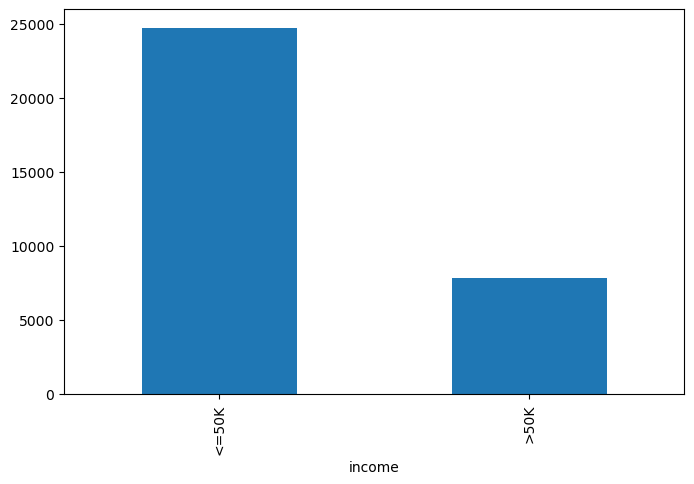

In [7]:
# Inspecting Target Column
import matplotlib.pyplot as plt
print(adult_train['income'].value_counts())
print(val:=adult_train['income'].value_counts(normalize=True)*100)
adult_train['income'].value_counts().plot(kind='bar',figsize=(8,5))
plt.show()

In [8]:
# Encoding Categorical Values
from sklearn.preprocessing import OneHotEncoder

X_train = adult_train.drop('income', axis=1)
y_train = adult_train['income']

X_test = adult_test.drop('income', axis=1)
y_test = adult_test['income']
categorical_columns=X_train.select_dtypes(include=['object']).columns
numerical_columns = X_train.select_dtypes(exclude=['object']).columns
encoder=OneHotEncoder(handle_unknown='ignore',sparse_output=False)
x_train_encoded=encoder.fit_transform(X_train[categorical_columns])
x_test_encoded=encoder.transform(X_test[categorical_columns])
encoded_cols=encoder.get_feature_names_out(categorical_columns)
X_train_encoded = pd.DataFrame(
    x_train_encoded,
    columns=encoded_cols,
    index=X_train.index
)

X_test_encoded = pd.DataFrame(
    x_test_encoded,
    columns=encoded_cols,
    index=X_test.index
)

X_train = pd.concat([X_train[numerical_columns], X_train_encoded], axis=1)
X_test = pd.concat([X_test[numerical_columns], X_test_encoded], axis=1)
print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)

print(X_train.head())
print(X_test.head())
y_test=y_test.str.strip().str.rstrip('.')

print("Training distribution:")
print(y_train.value_counts(normalize=True) * 100)

print("\nTesting distribution:")
print(y_test.value_counts(normalize=True) * 100)

y_test = adult_test['income'].str.strip().str.rstrip('.')
print(len(y_test))
print(len(dtc_pred))

Training shape: (32561, 108)
Testing shape: (16281, 108)
   age  fnlwgt  education-num  capital-gain  capital-loss  hours-per-week  \
0   39   77516             13          2174             0              40   
1   50   83311             13             0             0              13   
2   38  215646              9             0             0              40   
3   53  234721              7             0             0              40   
4   28  338409             13             0             0              40   

   workclass_Federal-gov  workclass_Local-gov  workclass_Never-worked  \
0                    0.0                  0.0                     0.0   
1                    0.0                  0.0                     0.0   
2                    0.0                  0.0                     0.0   
3                    0.0                  0.0                     0.0   
4                    0.0                  0.0                     0.0   

   workclass_Private  ...  native-country

0.8107610097659849
              precision    recall  f1-score   support

       <=50K       0.88      0.87      0.88     12435
        >50K       0.60      0.62      0.61      3846

    accuracy                           0.81     16281
   macro avg       0.74      0.75      0.74     16281
weighted avg       0.81      0.81      0.81     16281

[[10811  1624]
 [ 1457  2389]]


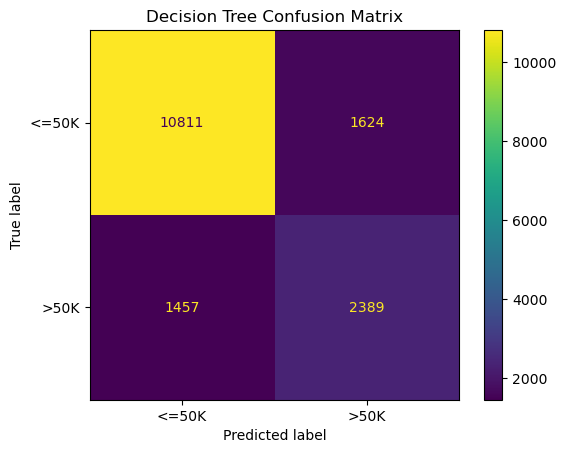

In [9]:
# DecisionTreeClassifier Algorithm

from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report,confusion_matrix,ConfusionMatrixDisplay

dtc_model=DecisionTreeClassifier(random_state=42)
dtc_model.fit(X_train,y_train)
dtc_pred=dtc_model.predict(X_test)
dtc_accuracy=accuracy_score(y_test,dtc_pred)
print(dtc_accuracy)
print(classification_report(y_test,dtc_pred))
print(confusion_matrix(y_test,dtc_pred))
ConfusionMatrixDisplay.from_predictions(y_test,dtc_pred)
plt.title("Decision Tree Confusion Matrix")
plt.show()

In [10]:
# RandomForestClassifier Algorithm
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold,cross_val_score
rfc=RandomForestClassifier(n_estimators=100,random_state=42)
rfc.fit(X_train,y_train)
rfc_pred=rfc.predict(X_test)
rfc_accuracy=accuracy_score(y_test,rfc_pred)
print(classification_report(y_test,rfc_pred))
print(confusion_matrix(y_test,rfc_pred))
# ConfusionMatrixDisplay.from_predictions(y_test,rfc_pred)
# plt.title("RandomForestClassifier Confusion Matrix")
# plt.show()


rfc_balanced=RandomForestClassifier(n_estimators=100,class_weight='balanced',random_state=42)
rfc_balanced.fit(X_train,y_train)
rfc_balanced_pred = rfc_balanced.predict(X_test)
print(classification_report(y_test, rfc_balanced_pred))

stf=StratifiedKFold(n_splits=5,shuffle=True,random_state=42)
rfc_cv=cross_val_score(rfc,X_train,y_train,cv=stf,scoring='accuracy')
print("CV Scores:", rfc_cv)
print("Mean Accuracy:", rfc_cv.mean())

              precision    recall  f1-score   support

       <=50K       0.88      0.93      0.90     12435
        >50K       0.72      0.61      0.66      3846

    accuracy                           0.85     16281
   macro avg       0.80      0.77      0.78     16281
weighted avg       0.84      0.85      0.85     16281

[[11507   928]
 [ 1512  2334]]
              precision    recall  f1-score   support

       <=50K       0.88      0.93      0.91     12435
        >50K       0.73      0.60      0.66      3846

    accuracy                           0.85     16281
   macro avg       0.80      0.77      0.78     16281
weighted avg       0.85      0.85      0.85     16281

CV Scores: [0.85290957 0.85795455 0.85534398 0.84797297 0.85764742]
Mean Accuracy: 0.8543656968806669


In [12]:
# Hyperparameter tuning
from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import f1_score,make_scorer
f1_scorer=make_scorer(f1_score,pos_label='>50K')
param_grid = {
    'n_estimators': [100, 200, 300],
    'max_depth': [10, 20, 30, None],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
    'max_features': ['sqrt', 'log2']
}
random_search=RandomizedSearchCV(estimator=RandomForestClassifier(random_state=42),param_distributions=param_grid,n_iter=10,cv=stf,scoring=f1_scorer,n_jobs=-1,verbose=1)
random_search.fit(X_train,y_train)

print(f" Best Parameters: {random_search.best_params_}")
print(f" Best CV: {random_search.best_score_}")
best_model=random_search.best_estimator_
tuned_pred=best_model.predict(X_test)
print(classification_report(y_test, tuned_pred))

feature_importance=pd.DataFrame({
    "Feature":X_train.columns,
    "Importance":best_model.feature_importances_
})
feature_importance=feature_importance.sort_values(by='Importance',ascending=False)
print(feature_importance.head(15))

Fitting 5 folds for each of 10 candidates, totalling 50 fits
 Best Parameters: {'n_estimators': 100, 'min_samples_split': 5, 'min_samples_leaf': 1, 'max_features': 'sqrt', 'max_depth': 30}
 Best CV: 0.6912740638782557
              precision    recall  f1-score   support

       <=50K       0.88      0.94      0.91     12435
        >50K       0.75      0.60      0.67      3846

    accuracy                           0.86     16281
   macro avg       0.82      0.77      0.79     16281
weighted avg       0.85      0.86      0.85     16281

                              Feature  Importance
3                        capital-gain    0.118201
0                                 age    0.114024
33  marital-status_Married-civ-spouse    0.088666
1                              fnlwgt    0.086439
2                       education-num    0.084198
5                      hours-per-week    0.069368
53               relationship_Husband    0.054720
4                        capital-loss    0.035537
35   

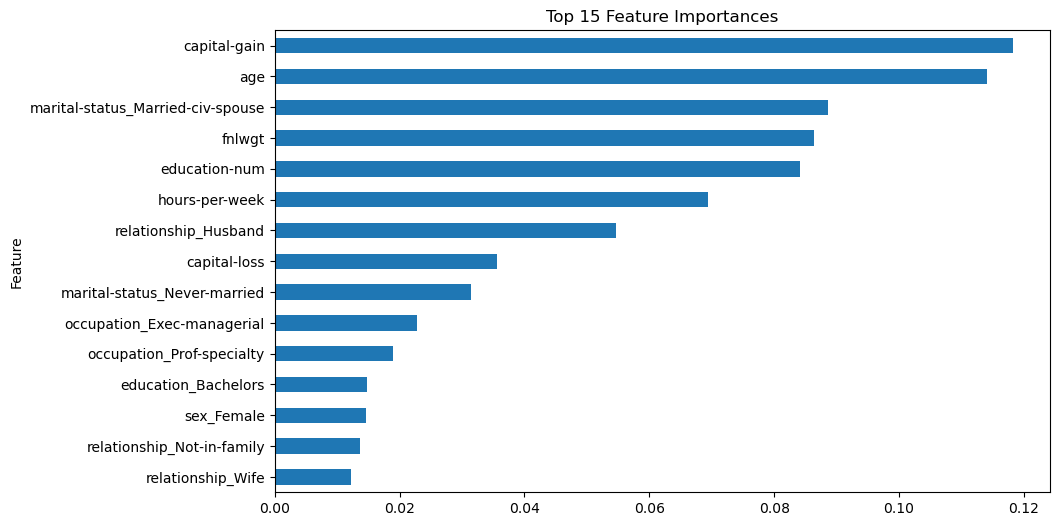

In [13]:
feature_importance.head(15).plot(x='Feature',
    y='Importance',
    kind='barh',
    figsize=(10, 6),
    legend=False)
plt.gca().invert_yaxis()
plt.title('Top 15 Feature Importances')
plt.show()

In [22]:
import joblib
joblib.dump(best_model, 'adult_income_model.pkl')
joblib.dump(encoder, 'adult_income_encoder.pkl')

['adult_income_encoder.pkl']

In [23]:
loaded_model = joblib.load('adult_income_model.pkl')
print(loaded_model)
loaded_encoder = joblib.load('adult_income_encoder.pkl')
print(loaded_encoder)
predictions = loaded_model.predict(X_test)

print(predictions[:10])
print(loaded_model.get_params())

RandomForestClassifier(max_depth=30, min_samples_split=5, random_state=42)
OneHotEncoder(handle_unknown='ignore', sparse_output=False)
['<=50K' '<=50K' '<=50K' '>50K' '<=50K' '<=50K' '<=50K' '>50K' '<=50K'
 '<=50K']
{'bootstrap': True, 'ccp_alpha': 0.0, 'class_weight': None, 'criterion': 'gini', 'max_depth': 30, 'max_features': 'sqrt', 'max_leaf_nodes': None, 'max_samples': None, 'min_impurity_decrease': 0.0, 'min_samples_leaf': 1, 'min_samples_split': 5, 'min_weight_fraction_leaf': 0.0, 'monotonic_cst': None, 'n_estimators': 100, 'n_jobs': None, 'oob_score': False, 'random_state': 42, 'verbose': 0, 'warm_start': False}


In [26]:
cd "C:\Users\antony remane\anaconda_projects\f8c2675d-5e87-4108-adcc-3a8325d2ecd4"

C:\Users\antony remane\anaconda_projects\f8c2675d-5e87-4108-adcc-3a8325d2ecd4
